# Apple Stock

### Introduction:

We are going to use Apple's stock price.


### Step 1. Import the necessary libraries

In [50]:
import pandas as pd
import numpy as np

### Step 2. Import the dataset from this [address](https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/09_Time_Series/Apple_Stock/appl_1980_2014.csv)

In [51]:
address = 'https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/09_Time_Series/Apple_Stock/appl_1980_2014.csv'
df = pd.read_csv(address)


### Step 3. Assign it to a variable apple and apply a head()

In [52]:
address = 'apple'
df.head()

,Date,Open,High,Low,Close,Volume,Adj Close
0,2014-07-08,96.27,96.80,93.92,95.35,65130000,95.35
1,2014-07-07,94.14,95.99,94.10,95.97,56305400,95.97
2,2014-07-03,93.67,94.10,93.20,94.03,22891800,94.03
3,2014-07-02,93.87,94.06,93.09,93.48,28420900,93.48
4,2014-07-01,93.52,94.07,93.13,93.52,38170200,93.52


### Step 4.  Check out the type of the columns

In [53]:
df.dtypes

Date             str
Open         float64
High         float64
Low          float64
Close        float64
Volume         int64
Adj Close    float64
dtype: object

### Step 5. Transform the Date column as a datetime type and check the info()

In [54]:
df["Date"] = pd.to_datetime(df["Date"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8465 entries, 0 to 8464
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       8465 non-null   datetime64[us]
 1   Open       8465 non-null   float64       
 2   High       8465 non-null   float64       
 3   Low        8465 non-null   float64       
 4   Close      8465 non-null   float64       
 5   Volume     8465 non-null   int64         
 6   Adj Close  8465 non-null   float64       
dtypes: datetime64[us](1), float64(5), int64(1)
memory usage: 463.1 KB


### Step 6.  Set the date as the index

In [55]:
df = df.set_index(['Date'])
df.head()

,Open,High,Low,Close,Volume,Adj Close
Date,,,,,,
2014-07-08,96.27,96.80,93.92,95.35,65130000,95.35
2014-07-07,94.14,95.99,94.10,95.97,56305400,95.97
2014-07-03,93.67,94.10,93.20,94.03,22891800,94.03
2014-07-02,93.87,94.06,93.09,93.48,28420900,93.48
2014-07-01,93.52,94.07,93.13,93.52,38170200,93.52


### Step 7.  Is there any duplicate dates?

In [56]:
df.index.duplicated().any()


np.False_

### Step 8.  Ops...it seems the index is from the most recent date. Make the first entry the oldest date.

In [57]:
df.sort_index()
df.head()

,Open,High,Low,Close,Volume,Adj Close
Date,,,,,,
2014-07-08,96.27,96.80,93.92,95.35,65130000,95.35
2014-07-07,94.14,95.99,94.10,95.97,56305400,95.97
2014-07-03,93.67,94.10,93.20,94.03,22891800,94.03
2014-07-02,93.87,94.06,93.09,93.48,28420900,93.48
2014-07-01,93.52,94.07,93.13,93.52,38170200,93.52


### Step 9. Get the last business day of each month

In [58]:
from pandas.tseries.offsets import BMonthEnd

print(df.index + BMonthEnd(0))

DatetimeIndex(['2014-07-31', '2014-07-31', '2014-07-31', '2014-07-31',
               '2014-07-31', '2014-06-30', '2014-06-30', '2014-06-30',
               '2014-06-30', '2014-06-30',
               ...
               '1980-12-31', '1980-12-31', '1980-12-31', '1980-12-31',
               '1980-12-31', '1980-12-31', '1980-12-31', '1980-12-31',
               '1980-12-31', '1980-12-31'],
              dtype='datetime64[us]', name='Date', length=8465, freq=None)


### Step 10.  What is the difference in days between the first day and the oldest

In [59]:
df.index.max() - df.index.min()

Timedelta('12261 days 00:00:00')

### Step 11.  How many months in the data we have?

In [60]:
df.index = df.index.to_period('M')
df.head()

,Open,High,Low,Close,Volume,Adj Close
Date,,,,,,
2014-07,96.27,96.80,93.92,95.35,65130000,95.35
2014-07,94.14,95.99,94.10,95.97,56305400,95.97
2014-07,93.67,94.10,93.20,94.03,22891800,94.03
2014-07,93.87,94.06,93.09,93.48,28420900,93.48
2014-07,93.52,94.07,93.13,93.52,38170200,93.52


In [61]:
df.index.nunique()

404

In [62]:
df.index.min()

Period('1980-12', 'M')

In [63]:
df.index.max()

Period('2014-07', 'M')

### Step 12. Plot the 'Adj Close' value. Set the size of the figure to 13.5 x 9 inches

In [64]:
import matplotlib.pyplot as plt

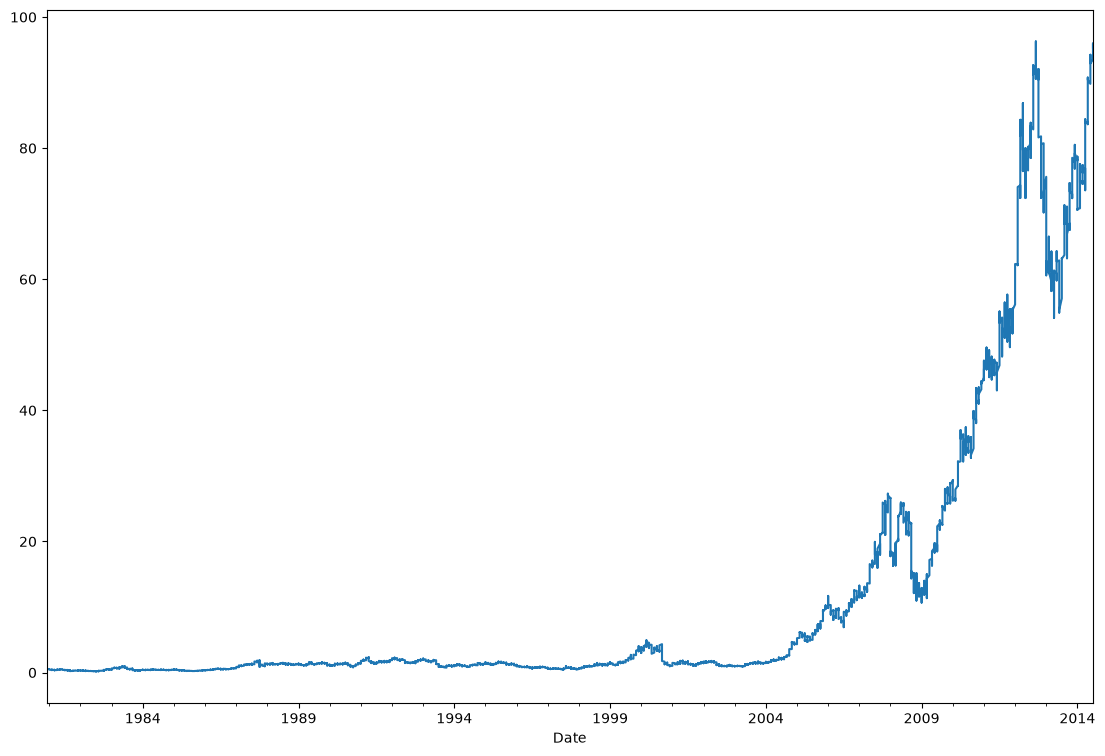

In [66]:
plt.figure(figsize=(13.5, 9))
df['Adj Close'].plot()

plt.show()